In [2]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path("../data/raw/sparcs_2024_raw.parquet")

df_raw = pd.read_parquet(DATA_PATH)

print(f"Dataset shape: {df_raw.shape}")

Dataset shape: (2196737, 33)


# Basic Inspections

In [3]:
pd.set_option('display.max_columns', None)
df_raw.head()

,health_service_area,hospital_county,operating_certificate_number,permanent_facility_id,facility_name,age_group,zip_code,gender,race,ethnicity,length_of_stay,type_of_admission,patient_disposition,discharge_year,ccsr_diagnosis_code,ccsr_diagnosis_description,apr_drg_code,apr_drg_description,apr_mdc_code,apr_mdc_description,apr_severity_of_illness_code,apr_severity_of_illness,apr_risk_of_mortality,apr_medical_surgical,payment_typology_1,emergency_department_indicator,total_charges,total_costs,ccsr_procedure_code,ccsr_procedure_description,payment_typology_2,birth_weight,payment_typology_3
0,Hudson Valley,Westchester,5957001,001139,WESTCHESTER MEDICAL CENTER,0-17,OOS,F,White,Not Span/Hispanic,1,Emergency,Home or Self Care,2024,SYM002,FEVER,722,FEVER AND INFLAMMATORY CONDITIONS,18,"INFECTIOUS AND PARASITIC DISEASES, SYSTEMIC OR...",2,Moderate,Minor,Medical,Private Health Insurance,Y,46814,6772.07,NaN,NaN,NaN,NaN,NaN
1,New York City,Queens,7003001,001628,FLUSHING HOSPITAL MEDICAL CENTER,0-17,113,M,White,Spanish/Hispanic,2,Emergency,Home or Self Care,2024,SYM002,FEVER,722,FEVER AND INFLAMMATORY CONDITIONS,18,"INFECTIOUS AND PARASITIC DISEASES, SYSTEMIC OR...",2,Moderate,Moderate,Medical,Medicaid,Y,13490,15464.3,NaN,NaN,NaN,NaN,NaN
2,New York City,New York,7002054,001458,NEW YORK-PRESBYTERIAN HOSPITAL - NEW YORK WEIL...,70 or Older,100,M,White,Not Span/Hispanic,2,Emergency,Home or Self Care,2024,SYM002,FEVER,722,FEVER AND INFLAMMATORY CONDITIONS,18,"INFECTIOUS AND PARASITIC DISEASES, SYSTEMIC OR...",2,Moderate,Moderate,Medical,Medicare,Y,49503.16,9324.77,ADM012,CHEMOTHERAPY,Private Health Insurance,NaN,NaN
3,New York City,New York,7002054,001464,NEW YORK-PRESBYTERIAN HOSPITAL - COLUMBIA PRES...,0-17,100,F,Other Race,Not Span/Hispanic,1,Emergency,Home or Self Care,2024,SYM002,FEVER,722,FEVER AND INFLAMMATORY CONDITIONS,18,"INFECTIOUS AND PARASITIC DISEASES, SYSTEMIC OR...",1,Minor,Minor,Medical,Private Health Insurance,Y,27827.66,7304.27,CNS002,LUMBAR PUNCTURE,NaN,2700,NaN
4,New York City,New York,7002032,001466,MOUNT SINAI WEST,18-29,100,F,Other Race,Spanish/Hispanic,1,Emergency,Home or Self Care,2024,SYM002,FEVER,722,FEVER AND INFLAMMATORY CONDITIONS,18,"INFECTIOUS AND PARASITIC DISEASES, SYSTEMIC OR...",2,Moderate,Minor,Medical,Medicare,Y,32798.29,7948.1,ADM021,"ADMINISTRATION OF THERAPEUTIC SUBSTANCES, NEC",NaN,NaN,NaN


In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 2196737 entries, 0 to 2196736
Data columns (total 33 columns):
 #   Column                          Dtype
---  ------                          -----
 0   health_service_area             str  
 1   hospital_county                 str  
 2   operating_certificate_number    str  
 3   permanent_facility_id           str  
 4   facility_name                   str  
 5   age_group                       str  
 6   zip_code                        str  
 7   gender                          str  
 8   race                            str  
 9   ethnicity                       str  
 10  length_of_stay                  str  
 11  type_of_admission               str  
 12  patient_disposition             str  
 13  discharge_year                  str  
 14  ccsr_diagnosis_code             str  
 15  ccsr_diagnosis_description      str  
 16  apr_drg_code                    str  
 17  apr_drg_description             str  
 18  apr_mdc_code                    s

In [5]:
columns_info = pd.DataFrame({
    "column": df_raw.columns,
    "non_null_count": df_raw.notna().sum().values,
    "missing_count": df_raw.isna().sum().values,
    "missing_pct": (df_raw.isna().mean() * 100).round(2).values,
    "unique_values": df_raw.nunique(dropna=True).values,
})

display(columns_info)

,column,non_null_count,missing_count,missing_pct,unique_values
0,health_service_area,2191442,5295,0.24,8
1,hospital_county,2191442,5295,0.24,57
2,operating_certificate_number,2191442,5295,0.24,158
3,permanent_facility_id,2191442,5295,0.24,205
4,facility_name,2196737,0,0.00,203
5,age_group,2196737,0,0.00,5
6,zip_code,2154765,41972,1.91,50
7,gender,2196737,0,0.00,3
8,race,2196737,0,0.00,4
9,ethnicity,2196737,0,0.00,4


In [6]:
df_raw.columns

Index(['health_service_area', 'hospital_county',
       'operating_certificate_number', 'permanent_facility_id',
       'facility_name', 'age_group', 'zip_code', 'gender', 'race', 'ethnicity',
       'length_of_stay', 'type_of_admission', 'patient_disposition',
       'discharge_year', 'ccsr_diagnosis_code', 'ccsr_diagnosis_description',
       'apr_drg_code', 'apr_drg_description', 'apr_mdc_code',
       'apr_mdc_description', 'apr_severity_of_illness_code',
       'apr_severity_of_illness', 'apr_risk_of_mortality',
       'apr_medical_surgical', 'payment_typology_1',
       'emergency_department_indicator', 'total_charges', 'total_costs',
       'ccsr_procedure_code', 'ccsr_procedure_description',
       'payment_typology_2', 'birth_weight', 'payment_typology_3'],
      dtype='str')

In [8]:
# Group 1: Columns that should/could be converted to numerical
numerical_cols = [
    "length_of_stay",
    "birth_weight",
]

# Group 2: Categorical columns
categorical_cols = [
    "health_service_area",
    "hospital_county",
    "operating_certificate_number",
    "permanent_facility_id",
    "facility_name",
    "age_group",
    "zip_code",
    "gender",
    "race",
    "ethnicity",
    "type_of_admission",
    "ccsr_diagnosis_code",
    "ccsr_diagnosis_description",
    "apr_drg_code",
    "apr_drg_description",
    "apr_mdc_code",
    "apr_mdc_description",
    "apr_severity_of_illness_code",
    "apr_severity_of_illness",
    "apr_risk_of_mortality",
    "apr_medical_surgical",
    "payment_typology_1",
    "payment_typology_2",
    "payment_typology_3",
    "emergency_department_indicator",
    "ccsr_procedure_code",
    "ccsr_procedure_description",
]

# Group 3: Exclude from the EDA working dataset
exclude_cols = [
    "patient_disposition",
    "discharge_year",
    "total_charges",
    "total_costs",
]

# Validate the groups against the raw dataframe
groups = {
    "numerical": numerical_cols,
    "categorical": categorical_cols,
    "excluded": exclude_cols,
}

assigned_cols = [
    col for cols in groups.values() for col in cols
]

assert len(assigned_cols) == len(set(assigned_cols)), (
    "A column appears in more than one group."
)
assert set(assigned_cols) == set(df_raw.columns), (
    f"Missing columns: {set(df_raw.columns) - set(assigned_cols)}; "
    f"unexpected columns: {set(assigned_cols) - set(df_raw.columns)}"
)

# Create a working copy; preserve df_raw
df_eda = df_raw.drop(columns=exclude_cols).copy()

print(f"Raw dataset shape: {df_raw.shape}")
print(f"EDA dataset shape: {df_eda.shape}")
print(f"Excluded columns: {exclude_cols}")

Raw dataset shape: (2196737, 33)
EDA dataset shape: (2196737, 29)
Excluded columns: ['patient_disposition', 'discharge_year', 'total_charges', 'total_costs']


In [9]:
import pandas as pd

# Birth weight: numeric in grams; missing values remain missing
df_eda["birth_weight"] = pd.to_numeric(
    df_eda["birth_weight"],
    errors="coerce"
)

# Length of stay: preserve the 120+ cap information
los_raw = df_eda["length_of_stay"].astype("string").str.strip()

df_eda["length_of_stay_capped"] = los_raw.eq("120+")

df_eda["length_of_stay"] = pd.to_numeric(
    los_raw.str.replace("+", "", regex=False),
    errors="coerce"
)

display(df_eda[numerical_cols].dtypes.to_frame("dtype"))

,dtype
length_of_stay,Int64
birth_weight,float64


In [10]:
for col in numerical_cols:
    print(f"\n{col}")
    print("Data type:", df_eda[col].dtype)
    print("Missing values:", f"{df_eda[col].isna().sum():,}")
    print("Unique numeric values:", f"{df_eda[col].nunique():,}")

display(df_eda[numerical_cols].describe().T)

print("\nCapped length-of-stay records:")
print(df_eda["length_of_stay_capped"].value_counts(dropna=False))



length_of_stay
Data type: Int64
Missing values: 0
Unique numeric values: 120

birth_weight
Data type: float64
Missing values: 1,989,037
Unique numeric values: 66


,count,mean,std,min,25%,50%,75%,max
length_of_stay,2196737.0,5.810259,8.826429,1.0,2.0,3.0,6.0,120.0
birth_weight,207700.0,3177.591237,577.821048,400.0,2900.0,3200.0,3500.0,9000.0



Capped length-of-stay records:
length_of_stay_capped
False    2194333
True        2404
Name: count, dtype: int64[pyarrow]


In [11]:
categorical_summary = pd.DataFrame({
    "dtype": df_eda[categorical_cols].dtypes.astype(str),
    "unique_values": df_eda[categorical_cols].nunique(dropna=True),
    "missing_count": df_eda[categorical_cols].isna().sum(),
    "missing_pct": (
        df_eda[categorical_cols].isna().mean() * 100
    ).round(2),
}).sort_values("unique_values", ascending=False)

display(categorical_summary)

,dtype,unique_values,missing_count,missing_pct
ccsr_diagnosis_code,str,478,0,0.00
ccsr_diagnosis_description,str,478,0,0.00
apr_drg_code,str,336,0,0.00
apr_drg_description,str,336,0,0.00
ccsr_procedure_description,str,320,643764,29.31
ccsr_procedure_code,str,320,643764,29.31
permanent_facility_id,str,205,5295,0.24
facility_name,str,203,0,0.00
operating_certificate_number,str,158,5295,0.24
hospital_county,str,57,5295,0.24


# Handling the Missing Values

In [15]:
missing_summary = pd.DataFrame({
    "missing_count": df_eda.isna().sum(),
    "missing_pct": (df_eda.isna().mean() * 100).round(2),
})

display(
    missing_summary[missing_summary["missing_count"] > 0]
    .sort_values("missing_pct", ascending=False)
)

,missing_count,missing_pct
birth_weight,1989037,90.55
payment_typology_3,1956699,89.07
payment_typology_2,1204408,54.83
ccsr_procedure_description,643764,29.31
ccsr_procedure_code,643764,29.31
zip_code,41972,1.91
health_service_area,5295,0.24
operating_certificate_number,5295,0.24
hospital_county,5295,0.24
permanent_facility_id,5295,0.24


In [56]:
birth_weight_missing = (
    df_eda.assign(
        birth_weight_missing=df_eda["birth_weight"].isna()
    )
    .groupby("type_of_admission", dropna=False)["birth_weight_missing"]
    .agg(["count", "mean"])
)

birth_weight_missing["missing_pct"] = (
    birth_weight_missing["mean"] * 100
).round(2)

display(birth_weight_missing.drop(columns="mean"))

,count,missing_pct
type_of_admission,,
Elective,355896,99.75
Emergency,1460204,99.57
Newborn,198219,0.07
Not Available,3652,99.15
Trauma,10050,99.82
Urgent,168716,98.56


Birth weight only reported for newborns. Could be seperated to train for newborns specifically.

In [23]:
procedure_missing = (
    df_eda.assign(
        procedure_missing=df_eda["ccsr_procedure_code"].isna()
    )
    .groupby("health_service_area", dropna=False)["procedure_missing"] #"type_of_admission"
    .agg(["count", "mean"])
)

procedure_missing["missing_pct"] = (
    procedure_missing["mean"] * 100
).round(2)

display(procedure_missing.drop(columns="mean"))

,count,missing_pct
health_service_area,,
Capital/Adirondacks,143613,38.67
Central NY,138048,30.51
Finger Lakes,140528,44.87
Hudson Valley,243870,38.02
Long Island,359214,33.19
New York City,996124,20.74
Southern Tier,28004,32.49
Western NY,142041,38.28
NaN,5295,20.23


In [18]:
payer_cols = [
    "payment_typology_1",
    "payment_typology_2",
    "payment_typology_3",
]

for col in payer_cols:
    print(f"\n{col}:")
    display(
        df_eda[col]
        .value_counts(dropna=False)
        .rename_axis("payer_category")
        .to_frame("count")
        .head(15)
    )


payment_typology_1:


,count
payer_category,
Medicare,929267
Medicaid,635606
Private Health Insurance,317827
Blue Cross/Blue Shield,204165
Self-Pay,34786
"Managed Care, Unspecified",30320
Miscellaneous/Other,21764
Federal/State/Local/VA,21140
Department of Corrections,1635



payment_typology_2:


,count
payer_category,
NaN,1204408
Medicaid,420954
Medicare,168543
Private Health Insurance,153534
Self-Pay,121540
Blue Cross/Blue Shield,105859
Federal/State/Local/VA,13178
"Managed Care, Unspecified",5527
Miscellaneous/Other,3081



payment_typology_3:


,count
payer_category,
NaN,1956699
Self-Pay,124253
Medicaid,67477
Private Health Insurance,19825
Blue Cross/Blue Shield,13845
Medicare,11800
Federal/State/Local/VA,2061
"Managed Care, Unspecified",470
Miscellaneous/Other,288


In [24]:
df_eda_clean = df_eda.copy()

# Categorical columns where missingness has a larger probability of meaning'Unknown' instead of not having one at all
unknown_category_cols = [
    "zip_code",
    "health_service_area",
    "operating_certificate_number",
    "hospital_county",
    "permanent_facility_id",
    "payment_typology_1",
]

for col in unknown_category_cols:
    df_eda_clean[col] = (
        df_eda_clean[col]
        .astype("string")
        .fillna("Unknown")
    )

# And those probably don't have one at all
preserve_missing_cols = [
    "birth_weight",
    "payment_typology_2",
    "payment_typology_3",
    "ccsr_procedure_code",
    "ccsr_procedure_description",
]

In [25]:
missing_summary = pd.DataFrame({
    "missing_count": df_eda_clean.isna().sum(),
    "missing_pct": (df_eda_clean.isna().mean() * 100).round(2),
})

display(
    missing_summary[missing_summary["missing_count"] > 0]
    .sort_values("missing_pct", ascending=False)
)

,missing_count,missing_pct
birth_weight,1989037,90.55
payment_typology_3,1956699,89.07
payment_typology_2,1204408,54.83
ccsr_procedure_code,643764,29.31
ccsr_procedure_description,643764,29.31


# Analysis

In [29]:
df_analysis = df_eda_clean.copy()

print(df_analysis["length_of_stay"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
))

print(
    "Capped Length of Stay Percentage:",
    round(df_analysis["length_of_stay_capped"].mean() * 100, 2), "%"
)

count    2196737.0
mean      5.810259
std       8.826429
min            1.0
25%            2.0
50%            3.0
75%            6.0
90%           12.0
95%           19.0
99%           42.0
max          120.0
Name: length_of_stay, dtype: Float64
Capped Length of Stay Percentage: 0.11 %


In [34]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------- ----- 8.1/9.5 MB 40.3 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 30.5 MB/s  0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 28.3 MB/s  0:00:00
   ---------------------------------------- 0.0/7.2 MB ? eta -:--:--
   ---------------------------------------  7.1/7.2 MB 45.9 MB/s eta 0:00:01
   ---------------------------------------- 7.2/7.2 MB 33.4 MB/s  0:00:00
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)

   ---------------------------------------- 0/7 [pyparsing]
   ---------------------------------------- 0/7 [pyparsing]
   ---------------------------------------- 0/7 [pyparsing

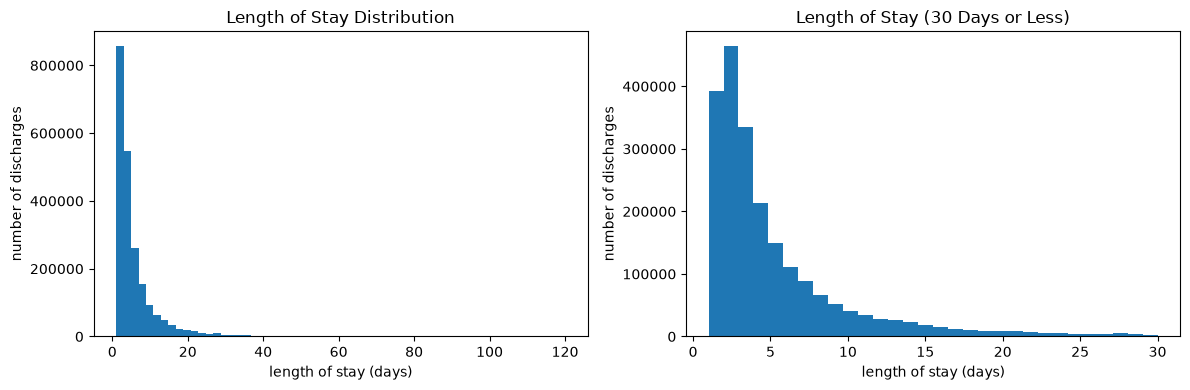

In [36]:
import matplotlib.pyplot as plt

los = df_analysis["length_of_stay"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(los, bins=60)
axes[0].set_title("Length of Stay Distribution")
axes[0].set_xlabel("length of stay (days)")
axes[0].set_ylabel("number of discharges")

axes[1].hist(los[los <= 30], bins=30)
axes[1].set_title("Length of Stay (30 Days or Less)")
axes[1].set_xlabel("length of stay (days)")
axes[1].set_ylabel("number of discharges")

plt.tight_layout()
plt.show()

In [33]:
categorical_features = [
    "health_service_area",
    "hospital_county",
    "operating_certificate_number",
    "permanent_facility_id",
    "facility_name",
    "age_group",
    "zip_code",
    "gender",
    "race",
    "ethnicity",
    "type_of_admission",
    "ccsr_diagnosis_code",
    "ccsr_diagnosis_description",
    "apr_drg_code",
    "apr_drg_description",
    "apr_mdc_code",
    "apr_mdc_description",
    "apr_severity_of_illness_code",
    "apr_severity_of_illness",
    "apr_risk_of_mortality",
    "apr_medical_surgical",
    "payment_typology_1",
    "payment_typology_2",
    "payment_typology_3",
    "emergency_department_indicator",
    "ccsr_procedure_code",
    "ccsr_procedure_description"
]

for col in categorical_features:
    print(f"\n--- {col} ---")
    print(df_analysis[col].value_counts(dropna=False).head(10))


--- health_service_area ---
health_service_area
New York City          996124
Long Island            359214
Hudson Valley          243870
Capital/Adirondacks    143613
Western NY             142041
Finger Lakes           140528
Central NY             138048
Southern Tier           28004
Unknown                  5295
Name: count, dtype: int64[pyarrow]

--- hospital_county ---
hospital_county
New York       389375
Kings          200536
Nassau         192048
Queens         185610
Suffolk        167166
Bronx          165312
Westchester    127036
Erie           112360
Monroe         105204
Onondaga        71592
Name: count, dtype: int64[pyarrow]

--- operating_certificate_number ---
operating_certificate_number
7002054    160737
7002053    124002
7003004     84433
7000006     78101
7002024     62960
2951001     53329
1401014     53212
7002032     44867
5151001     42272
7004003     40331
Name: count, dtype: int64[pyarrow]

--- permanent_facility_id ---
permanent_facility_id
001456    53353

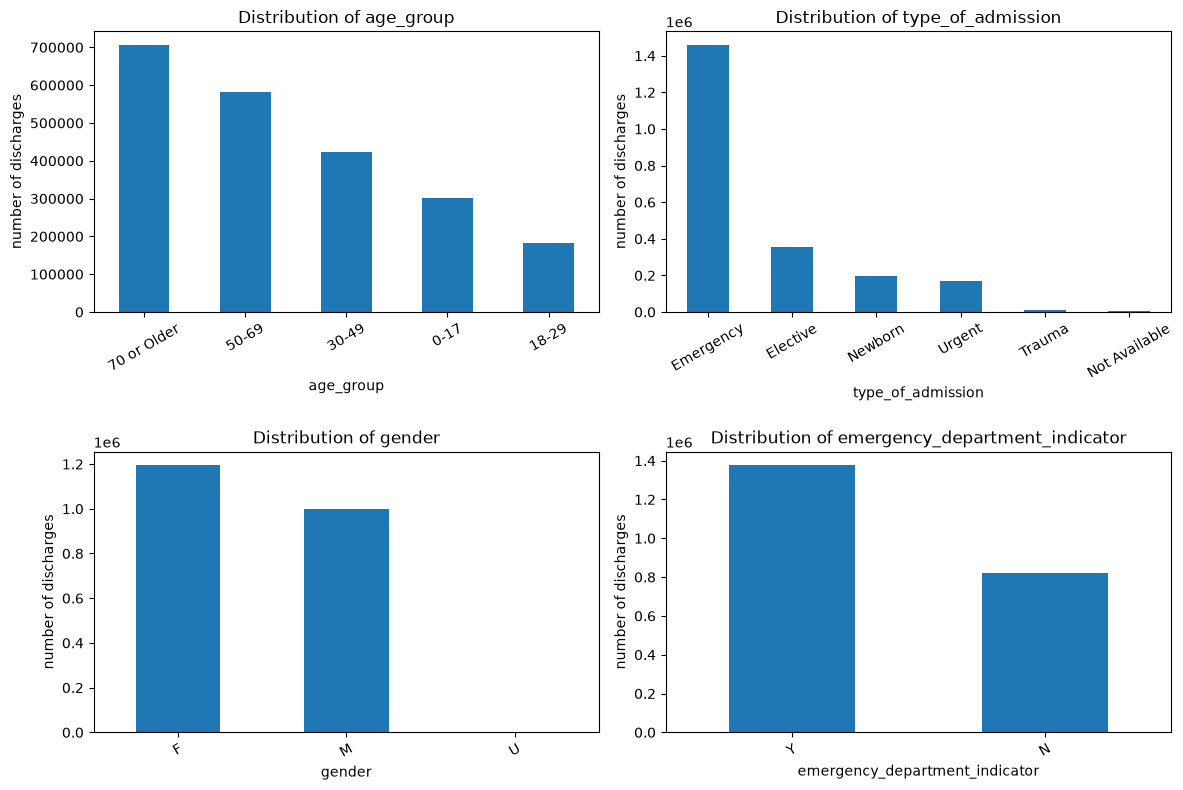

In [39]:
plot_features = [
    "age_group",
    "type_of_admission",
    "gender",
    "emergency_department_indicator",
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flat, plot_features):
    counts = df_analysis[col].value_counts(dropna=False)
    counts.plot(kind="bar", ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("number of discharges")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [40]:
bivariate = [
    "age_group",
    "gender",
    "race",
    "ethnicity",
    "type_of_admission",
    "emergency_department_indicator",
    "health_service_area",
]

for col in bivariate:
    summary = (
        df_analysis.groupby(col, dropna=False)["length_of_stay"]
        .agg(["count", "median", "mean"])
        .sort_values("median", ascending=False)
    )

    print(f"\n--- Length of Stay by {col} ---")
    print(summary.round(2))


--- Length of Stay by age_group ---
              count  median  mean
age_group                        
70 or Older  706970     4.0  6.53
50-69        581333     4.0  6.64
30-49        423270     3.0  5.19
18-29        183237     3.0  4.82
0-17         301927     2.0  4.01

--- Length of Stay by gender ---
          count  median  mean
gender                       
F       1195617     3.0  5.32
M       1000735     3.0  6.39
U           385     2.0  4.57

--- Length of Stay by race ---
                          count  median  mean
race                                         
Black/African American   395419     4.0  6.88
Multi-racial              33092     3.0  5.75
Other Race               620872     3.0  5.52
White                   1147354     3.0   5.6

--- Length of Stay by ethnicity ---
                     count  median  mean
ethnicity                               
Multi-ethnic          2568     4.0  5.82
Not Span/Hispanic  1540538     3.0  5.84
Spanish/Hispanic    363988     3

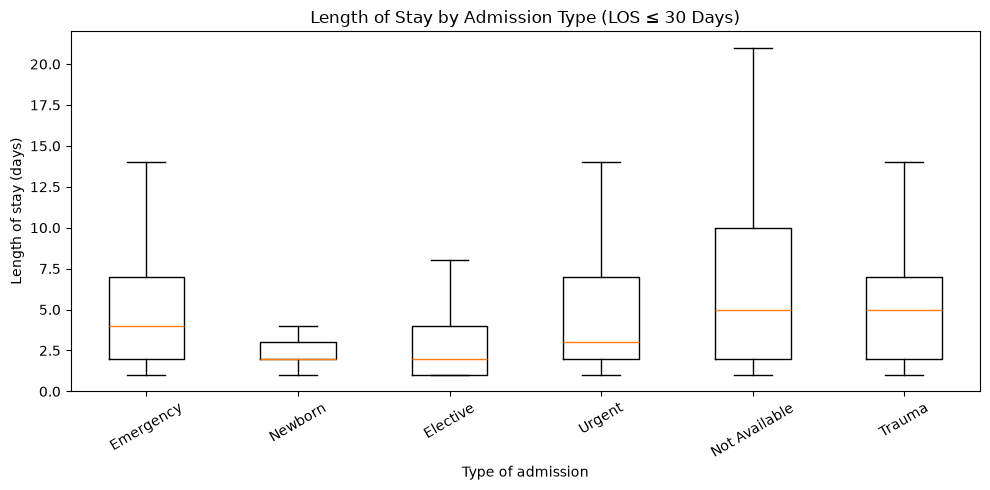

In [41]:
plot_df = df_analysis[
    ["type_of_admission", "length_of_stay"]
].dropna().sample(
    n=min(30_000, df_analysis["length_of_stay"].notna().sum()),
    random_state=42
)

plot_df = plot_df[plot_df["length_of_stay"] <= 30]

groups = [
    plot_df.loc[
        plot_df["type_of_admission"] == admission,
        "length_of_stay"
    ].values
    for admission in plot_df["type_of_admission"].dropna().unique()
]

labels = plot_df["type_of_admission"].dropna().unique()

plt.figure(figsize=(10, 5))
plt.boxplot(groups, tick_labels=labels, showfliers=False)
plt.title("Length of Stay by Admission Type (LOS ≤ 30 Days)")
plt.xlabel("Type of admission")
plt.ylabel("Length of stay (days)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

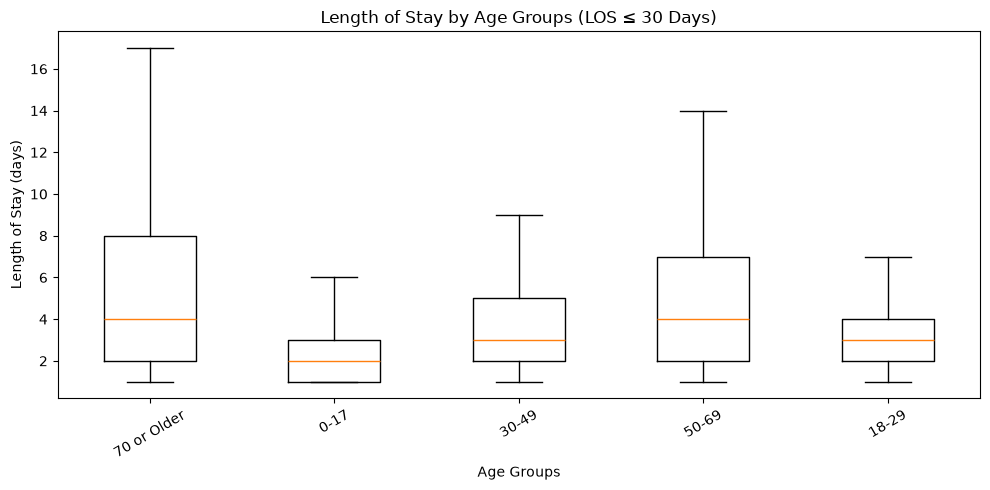

In [45]:
plot_df = df_analysis[
    ["age_group", "length_of_stay"]
].dropna().sample(
    n=min(30_000, df_analysis["length_of_stay"].notna().sum()),
    random_state=42
)

plot_df = plot_df[plot_df["length_of_stay"] <= 30]

groups = [
    plot_df.loc[
        plot_df["age_group"] == agegroup,
        "length_of_stay"
    ].values
    for agegroup in plot_df["age_group"].dropna().unique()
]

labels = plot_df["age_group"].dropna().unique()

plt.figure(figsize=(10, 5))
plt.boxplot(groups, tick_labels=labels, showfliers=False)
plt.title("Length of Stay by Age Groups (LOS ≤ 30 Days)")
plt.xlabel("Age Groups")
plt.ylabel("Length of Stay (days)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

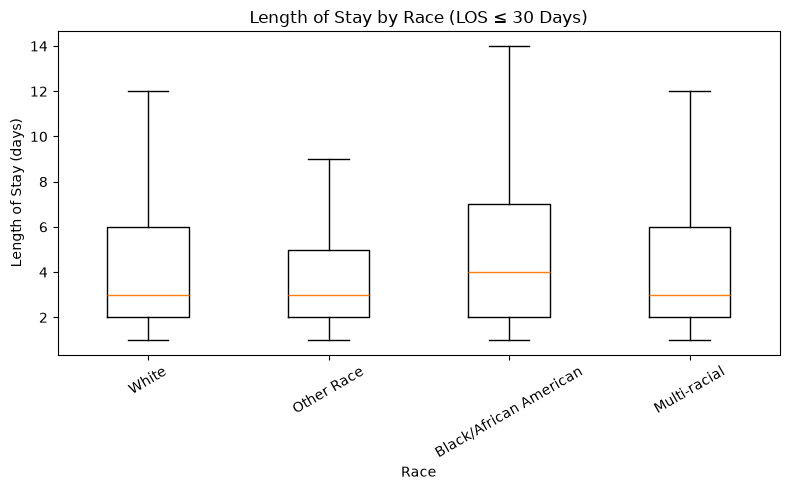

In [50]:
plot_df = df_analysis[
    ["race", "length_of_stay"]
].dropna().sample(
    n=min(30_000, df_analysis["length_of_stay"].notna().sum()),
    random_state=42
)

plot_df = plot_df[plot_df["length_of_stay"] <= 30]

groups = [
    plot_df.loc[
        plot_df["race"] == r,
        "length_of_stay"
    ].values
    for r in plot_df["race"].dropna().unique()
]

labels = plot_df["race"].dropna().unique()

plt.figure(figsize=(8, 5))
plt.boxplot(groups, tick_labels=labels, showfliers=False)
plt.title("Length of Stay by Race (LOS ≤ 30 Days)")
plt.xlabel("Race")
plt.ylabel("Length of Stay (days)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

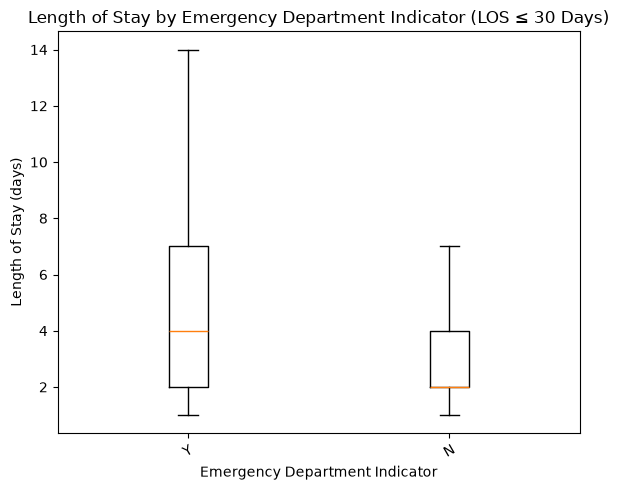

In [48]:
plot_df = df_analysis[
    ["emergency_department_indicator", "length_of_stay"]
].dropna().sample(
    n=min(30_000, df_analysis["length_of_stay"].notna().sum()),
    random_state=42
)

plot_df = plot_df[plot_df["length_of_stay"] <= 30]

groups = [
    plot_df.loc[
        plot_df["emergency_department_indicator"] == edi,
        "length_of_stay"
    ].values
    for edi in plot_df["emergency_department_indicator"].dropna().unique()
]

labels = plot_df["emergency_department_indicator"].dropna().unique()

plt.figure(figsize=(6, 5))
plt.boxplot(groups, tick_labels=labels, showfliers=False)
plt.title("Length of Stay by Emergency Department Indicator (LOS ≤ 30 Days)")
plt.xlabel("Emergency Department Indicator")
plt.ylabel("Length of Stay (days)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

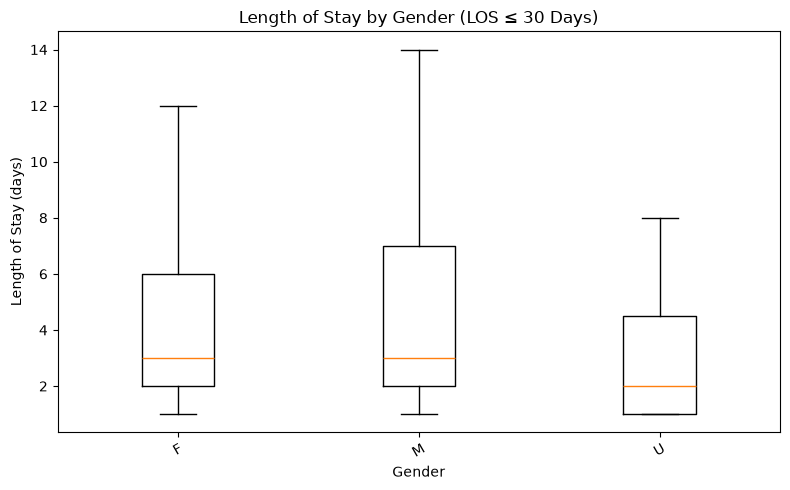

In [53]:
plot_df = df_analysis[
    ["gender", "length_of_stay"]
].dropna().sample(
    n=min(30_000, df_analysis["length_of_stay"].notna().sum()),
    random_state=42
)

plot_df = plot_df[plot_df["length_of_stay"] <= 30]

groups = [
    plot_df.loc[
        plot_df["gender"] == g,
        "length_of_stay"
    ].values
    for g in plot_df["gender"].dropna().unique()
]

labels = plot_df["gender"].dropna().unique()

plt.figure(figsize=(8, 5))
plt.boxplot(groups, tick_labels=labels, showfliers=False)
plt.title("Length of Stay by Gender (LOS ≤ 30 Days)")
plt.xlabel("Gender")
plt.ylabel("Length of Stay (days)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [51]:
group_cols = [
    "age_group",
    "type_of_admission",
    "emergency_department_indicator",
]

multivariate_summary = (
    df_analysis.groupby(group_cols, dropna=False)
    ["length_of_stay"]
    .agg(["count", "median", "mean"])
    .reset_index()
    .sort_values("median", ascending=False)
)

print(multivariate_summary.head(20))

      age_group type_of_admission emergency_department_indicator   count  \
40        50-69           Newborn                              N       1   
1          0-17          Elective                              Y     510   
43        50-69     Not Available                              Y     106   
42        50-69     Not Available                              N    1005   
54  70 or Older     Not Available                              N    1200   
46        50-69            Urgent                              N   35758   
59  70 or Older            Urgent                              Y    8057   
57  70 or Older            Trauma                              Y    4067   
37        50-69          Elective                              Y    1512   
56  70 or Older            Trauma                              N     254   
55  70 or Older     Not Available                              Y     112   
58  70 or Older            Urgent                              N   33189   
38        50